Device: cpu
Epoch    1 | loss(scaled)=0.6881 | Train RMSE=11.697, MAE=8.983, MAPE=25.23%, R2=0.669 | Val RMSE=12.111, MAE=9.375, MAPE=21.56%, R2=0.593
Epoch   25 | loss(scaled)=0.1512 | Train RMSE=7.331, MAE=5.493, MAPE=13.27%, R2=0.870 | Val RMSE=8.447, MAE=6.384, MAPE=13.44%, R2=0.802
Epoch   50 | loss(scaled)=0.1366 | Train RMSE=6.805, MAE=5.150, MAPE=12.88%, R2=0.888 | Val RMSE=7.689, MAE=5.874, MAPE=13.06%, R2=0.836
Epoch   75 | loss(scaled)=0.1285 | Train RMSE=6.536, MAE=4.866, MAPE=11.96%, R2=0.897 | Val RMSE=7.548, MAE=5.561, MAPE=12.31%, R2=0.842
Epoch  100 | loss(scaled)=0.1133 | Train RMSE=6.116, MAE=4.583, MAPE=11.07%, R2=0.910 | Val RMSE=7.150, MAE=5.354, MAPE=11.63%, R2=0.858
Epoch  125 | loss(scaled)=0.1223 | Train RMSE=6.016, MAE=4.469, MAPE=11.26%, R2=0.912 | Val RMSE=7.277, MAE=5.368, MAPE=11.93%, R2=0.853
Epoch  150 | loss(scaled)=0.1065 | Train RMSE=5.828, MAE=4.363, MAPE=10.65%, R2=0.918 | Val RMSE=7.048, MAE=5.221, MAPE=11.28%, R2=0.862
Epoch  175 | loss(scaled)=0

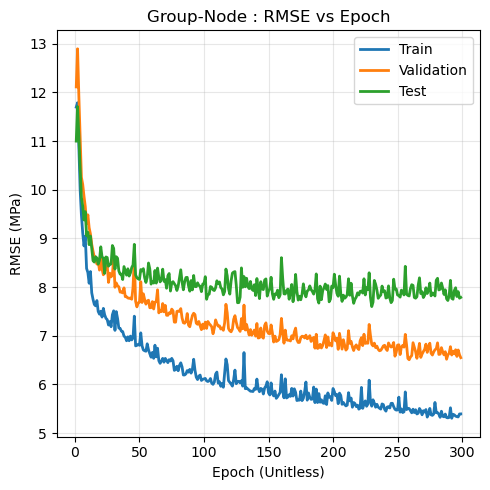

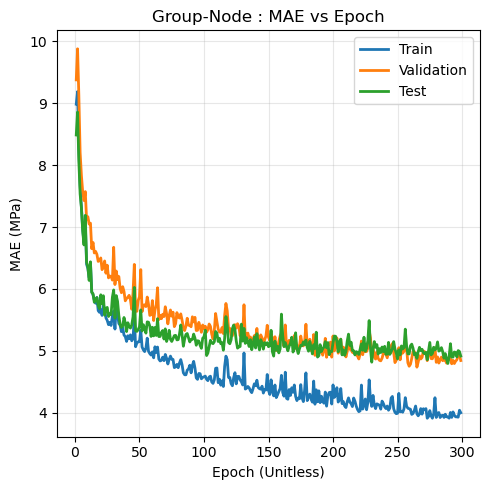

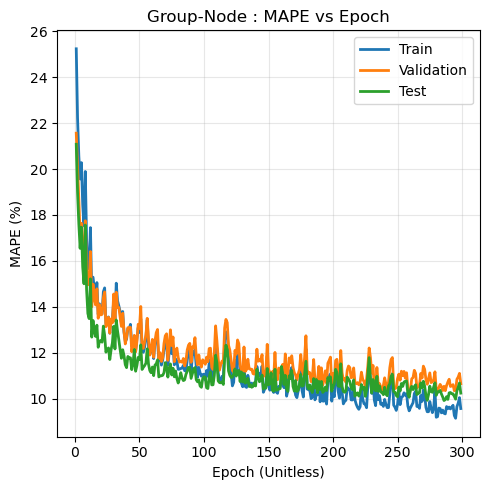

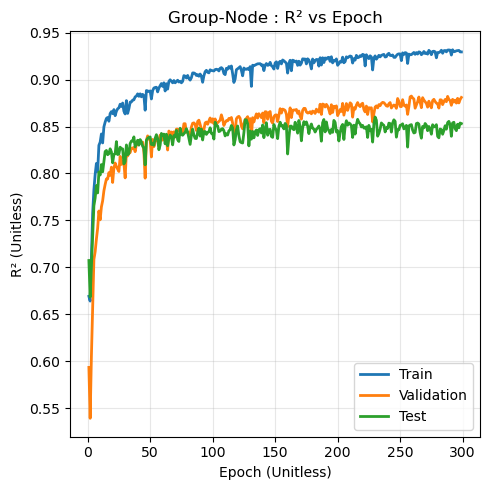

In [1]:
import re
import os
import joblib
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from torch_geometric.data import HeteroData
from torch_geometric.loader import DataLoader
from torch_geometric.nn import HeteroConv, SAGEConv

import matplotlib.pyplot as plt



# Repro + device
def set_seed(seed=42):
    import random
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)



# CONFIG: file + columns

EXCEL_PATH = "RILEM dataset.xlsx"
HEADER_ROW = 1  # headers are in row 2 -> header=1

TARGET_COL  = "FCXN_VALUE (N/mm²)"
CASTING_COL = "Casting Strength (MPa)"

PRINTING_COLS = [
    "nozzle travel velocity (mm/s)",
    "No. adjacent filaments",
    "layer height (mm)",
    "No. Layers",
    "vertical layer interval time (s)",
    "time mixing to print (s)",
    "Nozzle Type (1=circular; 2 =rectangular)",
    "nozzle diameter (mm)",
    "nozzle length (mm)",
    "nozzle width (mm)",
]

SAMPLE_COLS = [
    "age (day)",
    "Sample Location (1=top;2=middle;3=bottom;4=unknow)",
    "extraction method (1=sawing; 2=core drilling; 3=waterjet)",
    "Direction (1=u,2=v,3=w)",
    "Sample shape (1= cube; 2= cylinder)",
    "sample density (kg/m³)",
]



# EDGE LISTS
# bi=True => auto add reverse edge type
# Indices: 0=printing, 1=sample, 2=casting

MIDDLE_MIDDLE_EDGES = [
    ("middle", 0, 1, True),  # printing ↔ sample
    ("middle", 1, 2, True),  # sample ↔ casting
]

MIDDLE_TO_OUTPUT_EDGES = [
    ("printing", "to_out", "output", False),
    ("sample",   "to_out", "output", False),
    ("casting",  "to_out", "output", False),
]

# Curves option: compute test metrics every epoch (slower on CPU).
# If False, test metrics are computed only every 25 epochs (faster).

EVAL_TEST_EVERY_EPOCH = True



# Load + clean Excel headers

df = pd.read_excel(EXCEL_PATH, header=HEADER_ROW)

def clean_col(c):
    c = str(c)
    c = c.replace("\xa0", " ").replace("Â", "")
    c = re.sub(r"\s+", " ", c).strip()
    return c

df.columns = [clean_col(c) for c in df.columns]
TARGET_COL  = clean_col(TARGET_COL)
CASTING_COL = clean_col(CASTING_COL)
PRINTING_COLS = [clean_col(c) for c in PRINTING_COLS]
SAMPLE_COLS   = [clean_col(c) for c in SAMPLE_COLS]

needed = [TARGET_COL, CASTING_COL] + PRINTING_COLS + SAMPLE_COLS
missing = [c for c in needed if c not in df.columns]
if missing:
    raise ValueError("Missing columns in Excel (after cleaning):\n" + "\n".join(missing))

# Convert X and y to numeric (coerce bad strings to NaN), then drop NaNs
for c in (PRINTING_COLS + SAMPLE_COLS + [CASTING_COL, TARGET_COL]):
    df[c] = pd.to_numeric(df[c], errors="coerce")

df = df.dropna(subset=PRINTING_COLS + SAMPLE_COLS + [CASTING_COL, TARGET_COL]).reset_index(drop=True)



# Split

idx = np.arange(len(df))
train_idx, test_idx = train_test_split(idx, test_size=0.1, random_state=42)
train_idx, val_idx  = train_test_split(train_idx, test_size=0.111, random_state=42)  # ~10% val



# Scale X (fit on train only) + scale y (fit on train only)

X_cols = PRINTING_COLS + SAMPLE_COLS + [CASTING_COL]
x_scaler = StandardScaler()
x_scaler.fit(df.loc[train_idx, X_cols].values)

y_scaler = StandardScaler()
y_scaler.fit(df.loc[train_idx, [TARGET_COL]].values)

# Fast inverse transform for y

y_mean = float(y_scaler.mean_[0])
y_std  = float(y_scaler.scale_[0])

def scale_y(y_raw: float) -> float:
    return (y_raw - y_mean) / (y_std + 1e-12)

def inverse_scale_y(y_scaled_t: torch.Tensor) -> torch.Tensor:
    return y_scaled_t * (y_std + 1e-12) + y_mean

def get_scaled_row(i: int):
    raw_x = df.loc[i, X_cols].values.astype(float)
    xs    = x_scaler.transform([raw_x])[0]

    p = xs[:len(PRINTING_COLS)] 
    s = xs[len(PRINTING_COLS):len(PRINTING_COLS)+len(SAMPLE_COLS)]  
    c = xs[-1]  # scalar

    y_raw = float(df.loc[i, TARGET_COL])
    y_s   = scale_y(y_raw)
    return p, s, c, y_raw, y_s



# Graph builder (1 row = 1 graph)
# Vector nodes for printing/sample + scaled y

def build_graph(i: int) -> HeteroData:
    pvec, svec, cval, y_raw, y_s = get_scaled_row(i)
    data = HeteroData()

    data["printing"].x = torch.tensor(pvec, dtype=torch.float32).view(1, -1)  
    data["sample"].x   = torch.tensor(svec, dtype=torch.float32).view(1, -1)  
    data["casting"].x  = torch.tensor([[cval]], dtype=torch.float32)          

    data["output"].x = torch.zeros((1, 1), dtype=torch.float32)

    # scaled target for training + raw target for metrics/plots
    
    data["output"].y     = torch.tensor([y_s], dtype=torch.float32)
    data["output"].y_raw = torch.tensor([y_raw], dtype=torch.float32)

    def set_edge(src_type, rel, dst_type, pairs):
        if not pairs:
            return
        edge_index = torch.tensor(pairs, dtype=torch.long).t().contiguous()
        data[(src_type, rel, dst_type)].edge_index = edge_index

    def set_edge_bidir(src_type, rel, dst_type, pairs):
        set_edge(src_type, rel, dst_type, pairs)
        rev_pairs = [(b, a) for (a, b) in pairs]
        set_edge(dst_type, rel + "_rev", src_type, rev_pairs)

    # Middle↔Middle
    
    middle_map = {0: "printing", 1: "sample", 2: "casting"}
    for _, a, b, bi in MIDDLE_MIDDLE_EDGES:
        src = middle_map[a]
        dst = middle_map[b]
        rel = f"m_{a}_{b}"
        if bi:
            set_edge_bidir(src, rel, dst, [(0, 0)])
        else:
            set_edge(src, rel, dst, [(0, 0)])

    # Middle→Output
    for src, rel, dst, bi in MIDDLE_TO_OUTPUT_EDGES:
        if bi:
            set_edge_bidir(src, rel, dst, [(0, 0)])
        else:
            set_edge(src, rel, dst, [(0, 0)])

    return data


def build_dataset(idxs):
    return [build_graph(int(i)) for i in idxs]

train_set = build_dataset(train_idx)
val_set   = build_dataset(val_idx)
test_set  = build_dataset(test_idx)

train_loader = DataLoader(train_set, batch_size=128, shuffle=True)
val_loader   = DataLoader(val_set, batch_size=128, shuffle=False)
test_loader  = DataLoader(test_set, batch_size=128, shuffle=False)



# Model: HeteroConv + SAGEConv, predict at output (scaled)

class HeteroHierGNN(nn.Module):
    def __init__(self, hidden_dim=256, num_layers=2, dropout=0.10):
        super().__init__()
        self.hidden_dim = hidden_dim
        self.dropout = dropout

        self.lin_in = nn.ModuleDict({
            "printing": nn.Linear(len(PRINTING_COLS), hidden_dim),
            "sample":   nn.Linear(len(SAMPLE_COLS), hidden_dim),
            "casting":  nn.Linear(1, hidden_dim),
            "output":   nn.Linear(1, hidden_dim),
        })

        self.edge_convs = nn.ModuleList([nn.ModuleDict() for _ in range(num_layers)])

        self.head = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, 1),
        )

    def forward(self, data: HeteroData):
        x_dict = {ntype: F.relu(self.lin_in[ntype](x)) for ntype, x in data.x_dict.items()}
        edge_types = list(data.edge_index_dict.keys())

        for layer_convs in self.edge_convs:
            conv_dict = {}
            for (src, rel, dst) in edge_types:
                k = f"{src}__{rel}__{dst}"
                if k not in layer_convs:
                    layer_convs[k] = SAGEConv((-1, -1), self.hidden_dim)
                conv_dict[(src, rel, dst)] = layer_convs[k]

            out_dict = HeteroConv(conv_dict, aggr="mean")(x_dict, data.edge_index_dict)

            for ntype in out_dict:
                x_dict[ntype] = F.relu(out_dict[ntype] + x_dict[ntype])
                x_dict[ntype] = F.dropout(x_dict[ntype], p=self.dropout, training=self.training)

        return self.head(x_dict["output"]).view(-1)  # scaled y


model = HeteroHierGNN(hidden_dim=256, num_layers=2, dropout=0.10).to(device)
opt = torch.optim.AdamW(model.parameters(), lr=2e-3, weight_decay=1e-4)
loss_fn = nn.MSELoss()


# Metrics + loops (metrics in RAW y units)

def rmse_t(yhat, y): return float(torch.sqrt(torch.mean((yhat - y) ** 2)).cpu().item())
def mae_t(yhat, y):  return float(torch.mean(torch.abs(yhat - y)).cpu().item())
def r2_t(yhat, y):
    y_mean = torch.mean(y)
    ss_tot = torch.sum((y - y_mean) ** 2)
    ss_res = torch.sum((y - yhat) ** 2)
    return float((1 - ss_res / (ss_tot + 1e-12)).cpu().item())
def mape_t(yhat, y, eps=1e-6):
    return float(
        torch.mean(
            torch.abs((y - yhat) / torch.clamp(torch.abs(y), min=eps))
        ).cpu().item() * 100.0
    )

@torch.no_grad()
def eval_loader(loader):
    model.eval()
    yh_raw, yy_raw = [], []
    for batch in loader:
        batch = batch.to(device)
        pred_s = model(batch)                         # scaled pred
        y_raw  = batch["output"].y_raw.view(-1).to(device)
        pred_raw = inverse_scale_y(pred_s)            # raw pred

        yh_raw.append(pred_raw.detach().cpu())
        yy_raw.append(y_raw.detach().cpu())

    yhat = torch.cat(yh_raw)
    y    = torch.cat(yy_raw)
    return {
    "RMSE": rmse_t(yhat, y),
    "MAE":  mae_t(yhat, y),
    "MAPE": mape_t(yhat, y),
    "R2":   r2_t(yhat, y),
}


def train_one_epoch(loader):
    model.train()
    total = 0.0
    for batch in loader:
        batch = batch.to(device)
        pred_s = model(batch)
        y_s = batch["output"].y.view(-1).to(device)  # scaled target

        loss = loss_fn(pred_s, y_s)
        opt.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0)
        opt.step()

        total += loss.item() * y_s.size(0)
    return total / len(loader.dataset)



# Train + store curves (early stopping on Val RMSE)

best_val = 1e18
best_state = None
patience = 40
bad = 0

history = {
    "epoch": [],
    "loss_scaled": [],

    "train_rmse": [], "val_rmse": [], "test_rmse": [],
    "train_mae":  [], "val_mae":  [], "test_mae":  [],
    "train_r2":   [], "val_r2":   [], "test_r2":   [],
    "train_mape": [], "val_mape": [], "test_mape": [],
}

for epoch in range(1, 401):
    tr_loss = train_one_epoch(train_loader)

    tr_m = eval_loader(train_loader)
    val_m = eval_loader(val_loader)

    if EVAL_TEST_EVERY_EPOCH or (epoch == 1 or epoch % 25 == 0):
        test_m = eval_loader(test_loader)
    else:
        test_m = {"RMSE": np.nan, "MAE": np.nan, "R2": np.nan}

    # store
    
    history["epoch"].append(epoch)
    history["loss_scaled"].append(tr_loss)

    history["train_rmse"].append(tr_m["RMSE"])
    history["train_mae"].append(tr_m["MAE"])
    history["train_r2"].append(tr_m["R2"])

    history["val_rmse"].append(val_m["RMSE"])
    history["val_mae"].append(val_m["MAE"])
    history["val_r2"].append(val_m["R2"])

    history["test_rmse"].append(test_m["RMSE"])
    history["test_mae"].append(test_m["MAE"])
    history["test_r2"].append(test_m["R2"])

    history["train_mape"].append(tr_m["MAPE"])
    history["val_mape"].append(val_m["MAPE"])
    history["test_mape"].append(test_m["MAPE"])


    if epoch == 1 or epoch % 25 == 0:
        print(
    f"Epoch {epoch:4d} | loss(scaled)={tr_loss:.4f} | "
    f"Train RMSE={tr_m['RMSE']:.3f}, MAE={tr_m['MAE']:.3f}, "
    f"MAPE={tr_m['MAPE']:.2f}%, R2={tr_m['R2']:.3f} | "
    f"Val RMSE={val_m['RMSE']:.3f}, MAE={val_m['MAE']:.3f}, "
    f"MAPE={val_m['MAPE']:.2f}%, R2={val_m['R2']:.3f}"
)


    # early stopping on val RMSE

    if val_m["RMSE"] < best_val:
        best_val = val_m["RMSE"]
        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        bad = 0
    else:
        bad += 1
        if bad >= patience:
            print(f"Early stopping at epoch {epoch}. Best Val RMSE={best_val:.4f}")
            break

if best_state is not None:
    model.load_state_dict(best_state)



# Save pre-trained group-node PGNN

os.makedirs("pretrained_model", exist_ok=True)

# Save model weights and model metadata
model_state_cpu = {
    k: v.detach().cpu()
    for k, v in model.state_dict().items()
}

checkpoint = {
    "model_state_dict": model_state_cpu,

    "model_config": {
        "hidden_dim": 256,
        "num_layers": 2,
        "dropout": 0.10,
    },

    "training_config": {
        "batch_size": 128,
        "learning_rate": 2e-3,
        "weight_decay": 1e-4,
        "optimizer": "AdamW",
        "loss_function": "MSELoss",
        "early_stopping_patience": 40,
        "random_seed": 42,
    },

    "printing_cols": PRINTING_COLS,
    "sample_cols": SAMPLE_COLS,
    "casting_col": CASTING_COL,
    "target_col": TARGET_COL,
    "x_cols": X_cols,

    "best_validation_rmse": best_val,
}

torch.save(
    checkpoint,
    "pretrained_model/group_node_PGNN_pretrained.pt"
)

# Save exactly the same preprocessing scalers

joblib.dump(
    {
        "x_scaler": x_scaler,
        "y_scaler": y_scaler,
    },
    "pretrained_model/preprocessing_scalers.joblib"
)

print("Saved pre-trained model:")
print("pretrained_model/group_node_PGNN_pretrained.pt")

print("Saved preprocessing scalers:")
print("pretrained_model/preprocessing_scalers.joblib")



# Final Performance (MPa)

print("\n=== Final Performance (MPa) ===")
print("Train:", eval_loader(train_loader))
print("Val  :", eval_loader(val_loader))
print("Test :", eval_loader(test_loader))



# Plot Train / Val / Test vs Epoch (RMSE + MAE + R²)

epochs = np.array(history["epoch"])

plt.figure(figsize=(5, 5))
plt.plot(epochs, history["train_rmse"], linewidth=2)
plt.plot(epochs, history["val_rmse"], linewidth=2)
plt.plot(epochs, history["test_rmse"], linewidth=2)
plt.xlabel("Epoch (Unitless)")
plt.ylabel("RMSE (MPa)")
plt.title("Group-Node : RMSE vs Epoch")
plt.legend(["Train", "Validation", "Test"])
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

plt.figure(figsize=(5, 5))
plt.plot(epochs, history["train_mae"], linewidth=2)
plt.plot(epochs, history["val_mae"], linewidth=2)
plt.plot(epochs, history["test_mae"], linewidth=2)
plt.xlabel("Epoch (Unitless)")
plt.ylabel("MAE (MPa)")
plt.title("Group-Node : MAE vs Epoch")
plt.legend(["Train", "Validation", "Test"])
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

plt.figure(figsize=(5, 5))
plt.plot(epochs, history["train_mape"], linewidth=2)
plt.plot(epochs, history["val_mape"], linewidth=2)
plt.plot(epochs, history["test_mape"], linewidth=2)
plt.xlabel("Epoch (Unitless)")
plt.ylabel("MAPE (%)")
plt.title("Group-Node : MAPE vs Epoch")
plt.legend(["Train", "Validation", "Test"])
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


plt.figure(figsize=(5, 5))
plt.plot(epochs, history["train_r2"], linewidth=2)
plt.plot(epochs, history["val_r2"], linewidth=2)
plt.plot(epochs, history["test_r2"], linewidth=2)
plt.xlabel("Epoch (Unitless)")
plt.ylabel("R² (Unitless)")
plt.title("Group-Node : R² vs Epoch")
plt.legend(["Train", "Validation", "Test"])
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()



# True vs Predicted plots (Train/Val/Test)

@torch.no_grad()
def plot_true_vs_pred(loader, title, filename):
    model.eval()
    y_true, y_pred = [], []

    for batch in loader:
        batch = batch.to(device)
        pred_scaled = model(batch)
        pred_raw = inverse_scale_y(pred_scaled)
        y_raw = batch["output"].y_raw.view(-1)
        y_true.append(y_raw.cpu())
        y_pred.append(pred_raw.cpu())

    y_true = torch.cat(y_true).numpy()
    y_pred = torch.cat(y_pred).numpy()

    plt.figure(figsize=(5, 5))
    plt.scatter(y_true, y_pred, s=15)
    mn = min(y_true.min(), y_pred.min())
    mx = max(y_true.max(), y_pred.max())
    plt.plot([mn, mx], [mn, mx], "r--")
    plt.xlabel("Measured Strength")
    plt.ylabel("Predicted Strength")
    plt.title(title)
    plt.tight_layout()
    plt.show()
    